**ROLL NO : 24BAD087**  
**NAME : POOVIKA M**

**EXP NO : 8**

**TRAIN A SIMPLE AUTOENCODER FOR DIMENSIONALITY REDUCTION AND FEATURE LEARNING**

PART A - Import libraries and load dataset

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)


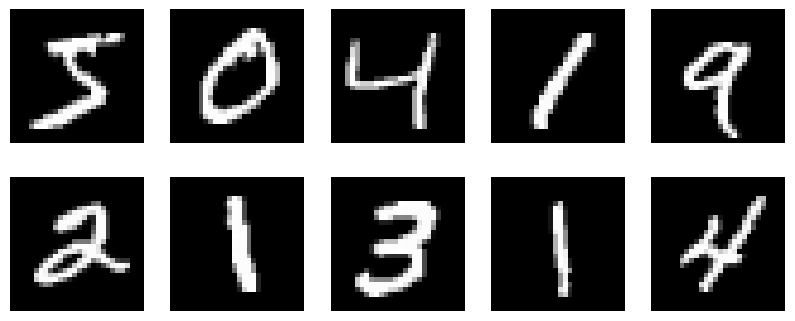

After flattening: (60000, 784)


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model

# Load MNIST dataset
(x_train, _), (x_test, _) = mnist.load_data()

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

# Display sample images
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.axis('off')

plt.show()

# Normalize pixel values
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Flatten images
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

print("After flattening:", x_train.shape)

PART B - Build encoder and decoder

In [2]:
# Encoder
input_layer = Input(shape=(784,))

encoded = Dense(128, activation='relu')(input_layer)
encoded = Dense(64, activation='relu')(encoded)

latent = Dense(32, activation='relu')(encoded)

# Decoder
decoded = Dense(64, activation='relu')(latent)
decoded = Dense(128, activation='relu')(decoded)

output_layer = Dense(784, activation='sigmoid')(decoded)

# Create models
autoencoder = Model(input_layer, output_layer)

encoder = Model(input_layer, latent)

decoder_input = Input(shape=(32,))
decoder_output = autoencoder.layers[-1](
    autoencoder.layers[-2](
        autoencoder.layers[-3](decoder_input)
    )
)

decoder = Model(decoder_input, decoder_output)

# Display model summaries
print("AUTOENCODER")
autoencoder.summary()

print("ENCODER")
encoder.summary()

print("DECODER")
decoder.summary()

AUTOENCODER


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)

... (8 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,568 (435.81 KB)

 Trainable params: 111,568 (435.81 KB)

 Non-trainable params: 0 (0.00 B)

PART C - Compile and train autoencoder

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - loss: 0.2478 - val_loss: 0.1688
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 10s 43ms/step - loss: 0.1503 - val_loss: 0.1353
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 0.1295 - val_loss: 0.1217
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - loss: 0.1201 - val_loss: 0.1154
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.1145 - val_loss: 0.1109
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.1104 - val_loss: 0.1072
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 27ms/step - loss: 0.1072 - val_loss: 0.1045
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.1047 - val_loss: 0.1026
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - loss: 0.1028 - val_loss: 0.1008
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 23ms/step - loss: 0.1013 - val_loss: 0.0994


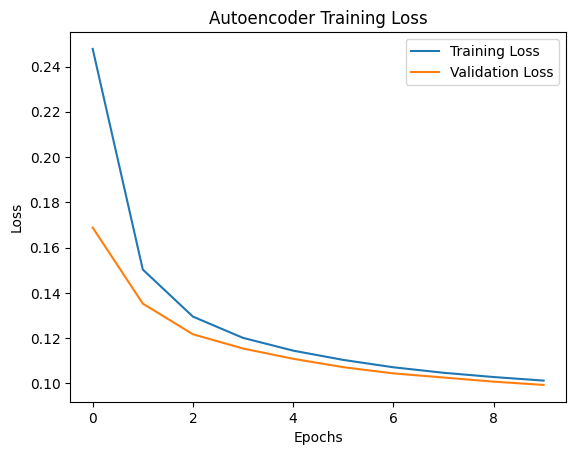

In [3]:
autoencoder.compile(
    optimizer='adam',
    loss='binary_crossentropy'
)

history = autoencoder.fit(
    x_train,
    x_train,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)

# Plot training and validation loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Autoencoder Training Loss')
plt.legend()
plt.show()

PART D - Dimensionality reduction and reconstruction

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Original dimension: 784
Reduced dimension: 32
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


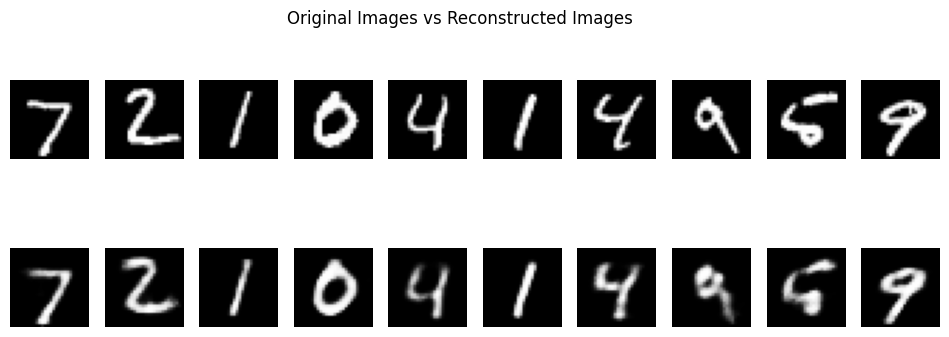

Autoencoder model saved successfully!


In [4]:
# Encode test images
encoded_images = encoder.predict(x_test)

print("Original dimension:", x_test.shape[1])
print("Reduced dimension:", encoded_images.shape[1])

# Reconstruct images
reconstructed_images = autoencoder.predict(x_test)

# Display original and reconstructed images
plt.figure(figsize=(12, 4))

for i in range(10):
    # Original images
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.axis('off')

    # Reconstructed images
    plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructed_images[i].reshape(28, 28), cmap='gray')
    plt.axis('off')

plt.suptitle("Original Images vs Reconstructed Images")
plt.show()

# Save model
autoencoder.save('autoencoder.keras')

print("Autoencoder model saved successfully!")